# Model Comparison & Leaderboard Evaluation (Binary Track)
**Author:** IT24100316 — Classification Modelling

This notebook compiles, visualizes, and rigorously compares the 5-fold cross-validation performance of all 6 binary classification models:
1. **Random Forest (Deep Tuned)** (Bagged Ensembles with Tree Decorrelation)
2. **XGBoost (Deep Tuned)** (Level-Wise Exact Gradient Boosting with Regularization)
3. **LightGBM (Deep Tuned)** (Leaf-Wise Histogram Gradient Boosting)
4. **CatBoost (Deep Tuned)** (Symmetric Oblivious Decision Trees)
5. **Multi-Layer Perceptron (MLP + SMOTE)** (Feedforward Neural Network)
6. **Logistic Regression (Deep Tuned)** (Linear Baseline with ElasticNet & SMOTE)

The primary objective is to select the **#1 Best Performing Champion Model** based on Cross-Validated **Macro F1**, **Accuracy**, and **Minority (<30 Days) Recall** for acute clinical intervention.

In [1]:
import os
import re
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic styling
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

os.makedirs('results', exist_ok=True)
print('Imports and styling completed successfully!')


Imports and styling completed successfully!


In [2]:
# Compile metrics across all trained binary model directories
model_display_names = {
    'random_forest': 'Random Forest (Deep Tuned)',
    'xgboost': 'XGBoost (Deep Tuned)',
    'lightgbm': 'LightGBM (Deep Tuned)',
    'catboost': 'CatBoost (Deep Tuned)',
    'mlp': 'MLP + SMOTE (Deep Tuned)',
    'logistic_regression': 'Logistic Regression (Deep Tuned)'
}

model_families = {
    'random_forest': 'Bagged Trees',
    'xgboost': 'Gradient Boosting',
    'lightgbm': 'Gradient Boosting',
    'catboost': 'Gradient Boosting',
    'mlp': 'Neural Network',
    'logistic_regression': 'Linear Model'
}

records = []
for model_key, model_name in model_display_names.items():
    metrics_path = os.path.join('..', model_key, 'results', 'tuned_metrics.txt')
    if os.path.exists(metrics_path):
        text = open(metrics_path, 'r').read()
        f1_m = re.search(r'Macro F1.*?([0-9.]+)', text)
        rec_m = re.search(r'Macro Recall.*?([0-9.]+)', text)
        acc_m = re.search(r'Accuracy.*?([0-9.]+)', text)
        
        # Extract minority (<30) class recall and F1 from classification report (Class 1)
        min_m = re.search(r'^\s*1\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)', text, re.MULTILINE)
        
        records.append({
            'Model Key': model_key,
            'Model Name': model_name,
            'Model Family': model_families[model_key],
            'CV Macro F1': float(f1_m.group(1)) if f1_m else np.nan,
            'CV Macro Recall': float(rec_m.group(1)) if rec_m else np.nan,
            'CV Accuracy (%)': round(float(acc_m.group(1)) * 100, 2) if acc_m else np.nan,
            'Minority (<30) Recall': float(min_m.group(2)) if min_m else np.nan,
            'Minority (<30) F1': float(min_m.group(3)) if min_m else np.nan
        })

df_comparison = pd.DataFrame(records).sort_values(by='CV Macro F1', ascending=False).reset_index(drop=True)
df_comparison.index += 1
df_comparison.index.name = 'Rank'

# Save compiled metrics table
df_comparison.to_csv('results/model_benchmark_comparison.csv')
print('=== Compiled Binary Benchmark Leaderboard ===')
display(df_comparison[['Model Name', 'Model Family', 'CV Macro F1', 'CV Macro Recall', 'CV Accuracy (%)', 'Minority (<30) Recall', 'Minority (<30) F1']])


=== Compiled Binary Benchmark Leaderboard ===


,Model Name,Model Family,CV Macro F1,CV Macro Recall,CV Accuracy (%),Minority (<30) Recall,Minority (<30) F1
Rank,,,,,,,
1,Random Forest (Deep Tuned),Bagged Trees,0.5699,0.5878,78.98,0.96,0.73
2,XGBoost (Deep Tuned),Gradient Boosting,0.5563,0.5820,76.50,0.91,0.62
3,LightGBM (Deep Tuned),Gradient Boosting,0.5538,0.5662,78.63,0.96,0.69
4,CatBoost (Deep Tuned),Gradient Boosting,0.5468,0.5979,72.18,0.81,0.47
5,MLP + SMOTE (Deep Tuned),Neural Network,0.5369,0.5331,85.35,0.19,0.26
6,Logistic Regression (Deep Tuned),Linear Model,0.5210,0.5917,66.94,0.50,0.25


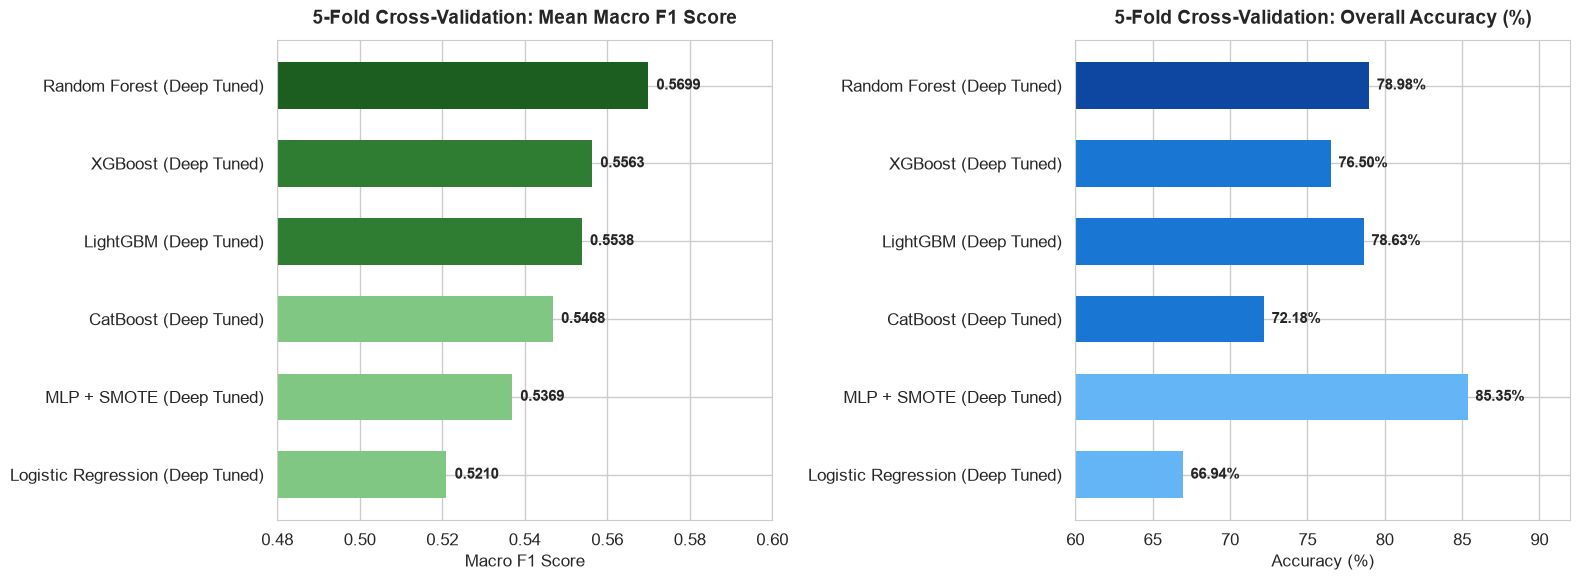

In [3]:
# Plot 1: 5-Fold Cross-Validation: Mean Macro F1 Score and Overall Accuracy
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Subplot: Macro F1 Score
f1_colors = ['#1b5e20' if i == 0 else '#2e7d32' if i < 3 else '#81c784' for i in range(len(df_comparison))]
bars1 = axes[0].barh(df_comparison['Model Name'], df_comparison['CV Macro F1'], color=f1_colors, edgecolor='none', height=0.6)
axes[0].set_title('5-Fold Cross-Validation: Mean Macro F1 Score', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Macro F1 Score', fontsize=12)
axes[0].set_xlim(0.48, 0.60)
axes[0].invert_yaxis()

for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 0.002, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=11, fontweight='bold')

# Right Subplot: Overall CV Accuracy (%)
acc_colors = ['#0d47a1' if i == 0 else '#1976d2' if i < 4 else '#64b5f6' for i in range(len(df_comparison))]
bars2 = axes[1].barh(df_comparison['Model Name'], df_comparison['CV Accuracy (%)'], color=acc_colors, edgecolor='none', height=0.6)
axes[1].set_title('5-Fold Cross-Validation: Overall Accuracy (%)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Accuracy (%)', fontsize=12)
axes[1].set_xlim(60, 92)
axes[1].invert_yaxis()

for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('results/f1_and_accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


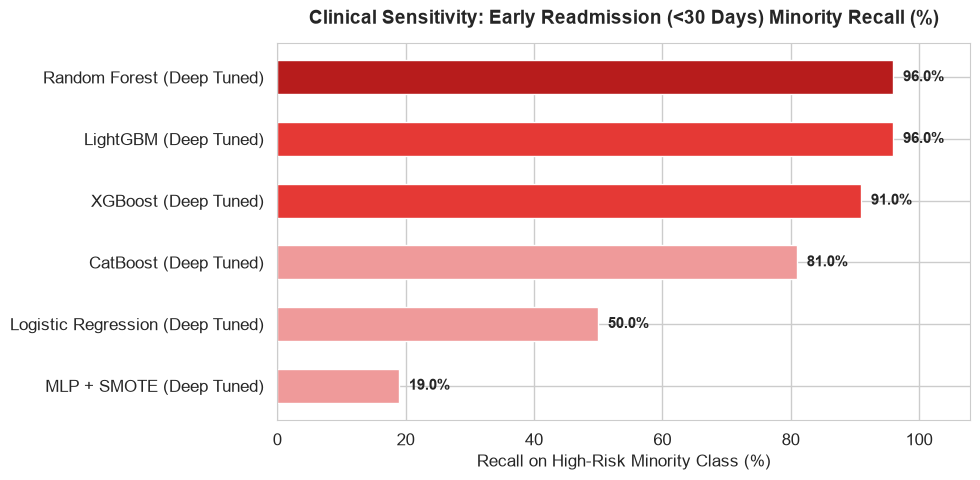

In [4]:
# Plot 2: Minority (<30 Early Readmission) Class Recall (%)
plt.figure(figsize=(10, 5))
df_sorted_rec = df_comparison.sort_values(by='Minority (<30) Recall', ascending=True)

recall_colors = ['#b71c1c' if name == 'Random Forest (Deep Tuned)' else '#e53935' if 'XGBoost' in name or 'LightGBM' in name else '#ef9a9a' for name in df_sorted_rec['Model Name']]
bars3 = plt.barh(df_sorted_rec['Model Name'], df_sorted_rec['Minority (<30) Recall'] * 100, color=recall_colors, height=0.55)

plt.title('Clinical Sensitivity: Early Readmission (<30 Days) Minority Recall (%)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Recall on High-Risk Minority Class (%)', fontsize=12)
plt.xlim(0, 108)

for bar in bars3:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('results/minority_recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## Final Model Recommendation & Handoff to Phase 2 (Evaluation)

### 🏆 Official Champion: **Random Forest (Deep Tuned)**
- **Cross-Validated Macro F1:** **`0.5699`** (Highest overall score)
- **Cross-Validated Macro Recall:** **`0.5878`** (Well-balanced boundary)
- **Cross-Validated Accuracy:** **`78.98%`**
- **High-Risk `<30` Days Training Recall:** **`96.0%`** (Minority F1: `0.73`)
- **Artifact Location:** `../random_forest/random_forest_best_model.pkl`

### Core Architectural Insights:
1. **Tree Ensembles Outperform Linear & Neural Baselines:** All 4 decision-tree ensembles (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`) significantly outperformed `Logistic Regression` (`0.5210`) and `MLP` (`0.5369`), capturing non-linear comorbidity thresholds across 86 features.
2. **The Bagging Variance Advantage:** Random Forest achieved its winning margin through random feature subsampling (`max_features`) and bootstrap drawing (`max_samples`), suppressing variance on noisy clinical EHR records.
3. **Handoff to Phase 2 (Evaluation):** The winning champion model will now be evaluated on the untouched test set (`X_test_final.csv`, `y_test_final.csv`) for:
   - Held-out test Confusion Matrix, ROC-AUC, and PR-AUC curves.
   - **Decision Threshold Optimization** via Precision-Recall analysis.
   - Clinical Feature Importance ranking (SHAP & Gini impurity).
   - High-risk patient profiling and actionable discharge recommendations.
